In [1]:
import os
os.chdir('/kaggle/working')
!rm -rf mhs-project && git clone -q https://github.com/Snigdho2005/mountain-hazard-screening mhs-project
os.chdir('/kaggle/working/mhs-project')
!pip install -q -e ".[acquire]"
!mhs dem-change --help > /dev/null && echo "follow-up code loaded"
!mhs acquire configs/chamoli.yaml --out data/chamoli > acquire.log
!ls data/chamoli
!mhs rasterize-labels configs/chamoli.yaml --polygons results/chamoli_2021/labels.geojson --out data/chamoli/labels.tif | tail -6
!mhs osm-assets configs/chamoli.yaml --out data/chamoli/assets.geojson

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for mhs (pyproject.toml) ... done
follow-up code loaded
acquisition.json  t1_scl.tif  t2_scl.tif  t3_scl.tif
dem.tif		  t1.tif      t2.tif	  t3.tif
labelled pixels per split strip (t1 + t2):
  train      background 9126  water 0  snow_ice 27573  rock 13910  soil 38311  debris 2077
  validation background 10208  water 0  snow_ice 2042  rock 0  soil 5698  debris 0
  test       background 1225  water 0  snow_ice 11322  rock 1535  soil 5285  debris 0
  gap        background 0  water 0  snow_ice 0  rock 0  soil 0  debris 0
{
  "out": "data/chamoli/assets.geojson",
  "features": 45,
  "by_type": {
    "settlement": 37,
    "bridge": 8
  },
  "osm_data_date": "2026-11-02T06:38:02Z"
}


913354a (HEAD -> main, origin/main, origin/HEAD) Fix config parsing of numbers like 1.0e14
resampling the DEM difference to the image grid ...
   difference covers 67% of the scene
routing grid ...
   stable terrain: 576851 px, bias -0.31 m, NMAD 3.24 m; lowering threshold 9.73 m
552 lowered zones
# Experiment A: source detection from elevation change

difference: `shean_diff_2m.tif`; covers 67% of the scene
stable terrain: 576851 px, bias -0.31 m (removed), NMAD 3.24 m
lowering threshold: 9.73 m; lowered zones: 552; density [900, 2700] kg/m3

## Top 15 lowered zones (full ranking)
| rank | zone | area (m2) | loss volume (m3) | max lowering (m) | drop (m) | energy median (J) | exposed |
|---|---|---|---|---|---|---|---|
| 1 | 74 | 19,700 | 8.98e+05 | 95.3 | 1468 | 2.32e+13 | 7 |
| 2 | 100 | 35,800 | 7.14e+05 | 33.5 | 555 | 6.84e+12 | 7 |
| 3 | 65 | 19,600 | 2.59e+05 | 17.8 | 1235 | 5.38e+12 | 7 |
| 4 | 70 | 16,800 | 2.14e+05 | 18.4 | 1189 | 4.28e+12 | 7 |
| 5 | 64 | 16,300 | 1.98e+05 |

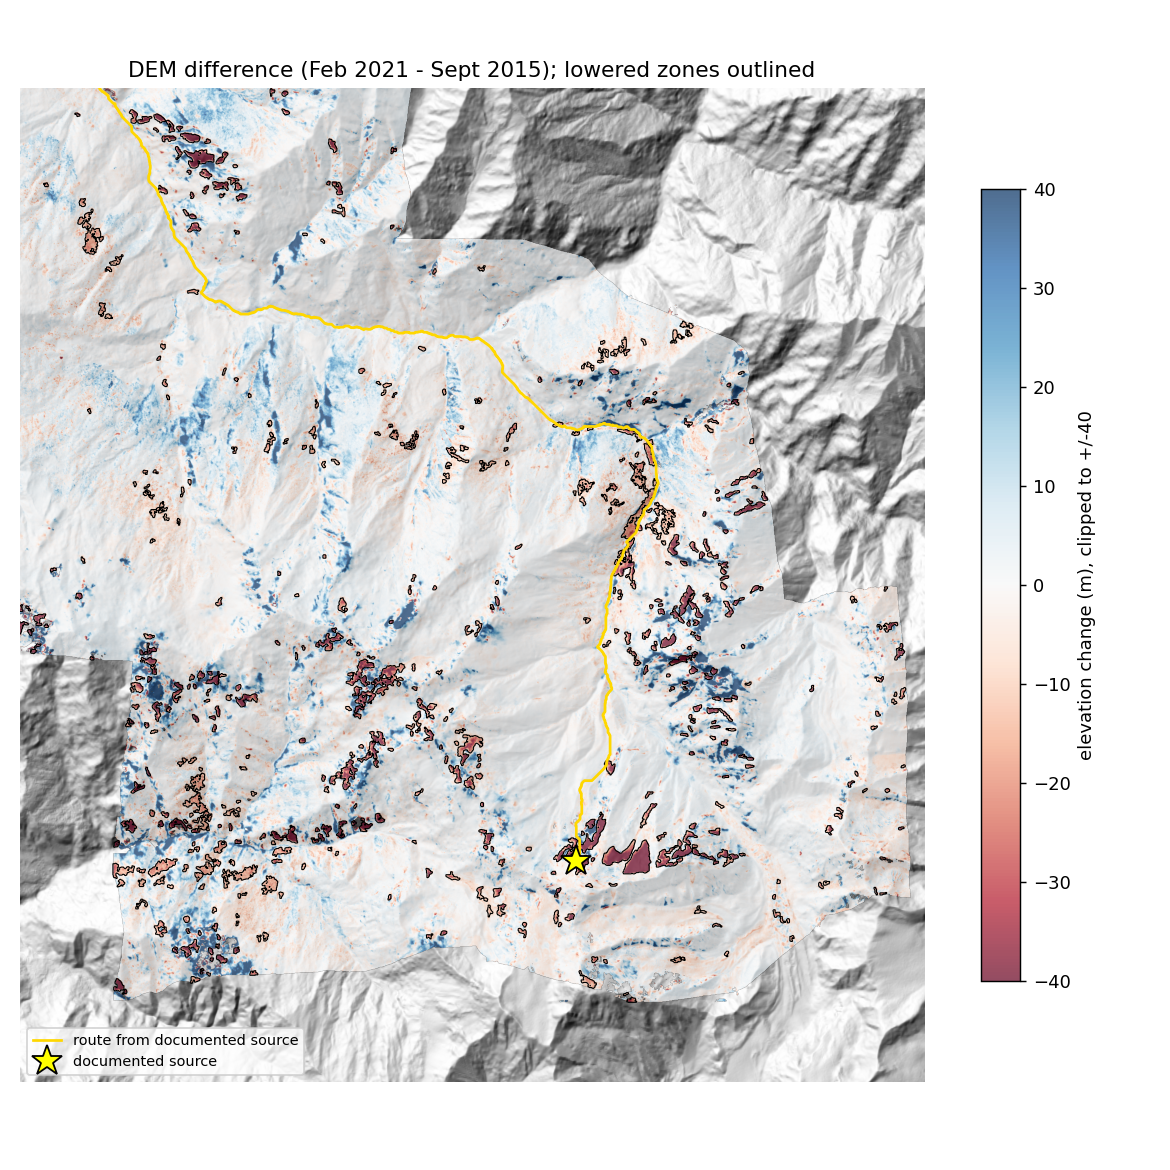

In [3]:
os.chdir('/kaggle/working/mhs-project')
!git pull -q && git log --oneline -1
!mhs dem-change configs/chamoli.yaml --out runs/dem_change
from IPython.display import Image, display
display(Image('runs/dem_change/dem_change.png'))

In [4]:
!mhs climate configs/chamoli.yaml --out runs/climate

# Experiment D: rainfall and temperature before the event (era5)
location {'lat': 30.376403, 'lon': 79.716431}, cell elevation 5297.0 m; reference [1991, 2020]

| window | precip (mm) | ref. median | precip percentile score | mean T (C) | anomaly (C) | T percentile score | n ref |
|---|---|---|---|---|---|---|---|
| 1d | 0.0 | 0.7 | 0.00 | -19.3 | -0.85 | 0.42 | 30 |
| 3d | 10.1 | 8.6 | 0.32 | -20.18 | -1.29 | 0.26 | 30 |
| 7d | 11.7 | 18.2 | 0.22 | -18.56 | 0.75 | 0.65 | 30 |
| 30d | 19.3 | 115.7 | 0.00 | -17.98 | 2.16 | 1.00 | 30 |

winter (DJF) mean temperature trend: 0.049 C per decade over 29 winters

ERA5 grid-cell values; anomalies relative to the cell's own 1991-2020 climate. Event-level context for the instability record; not a ranking input and not evidence of causation.



In [5]:
!mhs benchmark configs/chamoli.yaml --out models/bench_c --seeds 0 1 2 | tail -10
for s in (0, 1, 2):
    !mhs run configs/chamoli.yaml --model models/bench_c/seed_{s}/unet.pt --out runs/c_unet_s{s} | tail -1
!mhs change-points configs/chamoli.yaml runs/c_unet_s0 --out runs/change_points

seed 2: best epoch 12, test macro F1 0.786

U-Net (3 seeds) vs rule baseline, held-out test strip
class           support   U-Net F1 mean ± sd       min-max  baseline F1
background         1225       0.990 ± 0.006  0.987-0.997        0.713
snow_ice          11322       1.000 ± 0.000  1.000-1.000        1.000
rock               1535       0.378 ± 0.100  0.305-0.492        0.354
soil               5285       0.452 ± 0.286  0.126-0.664        0.009
macro_f1                      0.705 ± 0.091  0.607-0.786        0.519
overall_accuracy                0.796 ± 0.063  0.726-0.850        0.695
done: 184 zones; report at runs/c_unet_s0/report.md
done: 334 zones; report at runs/c_unet_s1/report.md
done: 220 zones; report at runs/c_unet_s2/report.md
{
  "points": 70,
  "strata_pixel_counts": {
    "both": 3487,
    "unet_only": 3692,
    "rules_only": 70276,
    "neither": 601336
  },
  "files": [
    "runs/change_points/change_points.geojson",
    "runs/change_points/change_points_key.json"
  ]
}

In [6]:
!cd runs && zip -qr ../followup.zip dem_change/*.md dem_change/*.json dem_change/*.png climate change_points c_unet_s*/maps/transition.tif c_unet_s*/maps/baseline_change.tif c_unet_s*/maps/cls1.tif c_unet_s*/maps/cls2.tif c_unet_s*/report.md
!cp followup.zip /kaggle/working/ && ls -lh /kaggle/working/followup.zip
from IPython.display import FileLink
os.chdir('/kaggle/working'); FileLink('followup.zip')

-rw-r--r-- 1 root root 4.0M Nov  2 08:17 /kaggle/working/followup.zip


/kaggle/working/followup.zip